# 🌍 Sprint 1 — Business & Data Understanding
**Projeto:** Language Identification (IA III / ML III) · **Dataset:** `zarajamshaid/language-identification-datasst`
**Metodologias:** SCRUM + CRISP-ML(Q) · **Notebook seguinte:** `02_Sprint2_Data_Preparation.ipynb`

| Notebook | Sprint | Conteúdo |
|---|---|---|
| **01 (este)** | 1 | ML Canvas, contrato de dados, EDA, correlações, probabilidades |
| 02 | 2 | Limpeza, split, features, scaling, desbalanceamento |
| 03 | 3 | Modelação supervisionada (sklearn + TensorFlow) |
| 04 | 4 | Avaliação, sistema multiagente, deployment simulado |

## 1.1 Machine Learning Canvas
| Bloco | Descrição |
|---|---|
| **Value proposition** | Identificar automaticamente o idioma de um texto para encaminhamento (tradução, moderação, suporte) |
| **Decisions** | Escolher o pipeline/idioma de destino; sinalizar textos com baixa confiança para revisão humana |
| **ML task** | Classificação multiclasse supervisionada (texto → idioma) |
| **Data sources** | Dataset Kaggle (texto + rótulo de idioma) |
| **Features** | n-gramas de caracteres (TF-IDF) + estatísticas do texto |
| **Making predictions** | Em tempo real, por pedido |
| **Offline evaluation** | Accuracy, **F1-macro**, matriz de confusão |
| **Monitoring** | % de predições com baixa confiança; distribuição de idiomas previstos vs. baseline |
| **Build/Update** | Re-treino quando houver *drift* ou novos idiomas |

## 1.2 Critérios de sucesso (CRISP-ML(Q))
- **Negócio:** F1-macro ≥ 0.95 no teste; latência < 50 ms por texto.
- **Dados:** contrato validado; sem fuga de informação entre splits.
- **Qualidade:** testar casos extremos (texto curto, vazio, só números, misto) e monitorizar a confiança.

In [7]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


In [11]:
# ---- Setup (descomenta o pip se faltarem pacotes) ----
!pip install kagglehub 


import os, sys, glob, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import joblib
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
for d in ["models", "reports", "data"]:
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, os.path.abspath("src"))   # executar o notebook na raiz do projeto (onde está a pasta src/)

  Using cached kagglehub-1.0.3-py3-none-any.whl.metadata (40 kB)
  Using cached kagglesdk-0.1.38-py3-none-any.whl.metadata (13 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached kagglehub-1.0.3-py3-none-any.whl (73 kB)
Using cached kagglesdk-0.1.38-py3-none-any.whl (290 kB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)

   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   -------------------------- ------------- 2/3 [kagglehub]
   -------------------------- ------------- 2/3 [kagglehub]
   ---------------------------------------- 3/3 [kagglehub]



## 1.3 Carregar dados e contrato de dados

In [16]:
from utils import detect_columns, clean_text, dominant_script, text_features, iqr_bounds, evaluate_model
from data_loader import load_raw

df = load_raw()
df = df.replace({'Portugese': 'Portuguese'})   # correção do rótulo mal escrito no dataset
df
TEXT_COL, LABEL_COL = "Text", "language"          # ex.: TEXT_COL, LABEL_COL = "Text", "Language"
if TEXT_COL is None or LABEL_COL is None:
    TEXT_COL, LABEL_COL = detect_columns(df)
print(f"Texto: {TEXT_COL!r} | Rótulo: {LABEL_COL!r}")
print("Idiomas:", sorted(df[LABEL_COL].astype(str).unique()))

from data_contract import build_contract, validate_contract
CONTRACT = build_contract(TEXT_COL, LABEL_COL, df[LABEL_COL].nunique())
print(json.dumps(CONTRACT, indent=2, ensure_ascii=False))
json.dump(CONTRACT, open("reports/data_contract.json", "w"), indent=2, ensure_ascii=False)
pd.DataFrame(validate_contract(df, CONTRACT), columns=["verificação", "passou", "detalhe"])

Ficheiros CSV encontrados: ['dataset.csv']
Texto: 'Text' | Rótulo: 'language'
Idiomas: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portuguese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']
{
  "dataset": "zarajamshaid/language-identification-datasst",
  "format": "CSV (UTF-8), uma linha por amostra",
  "columns": {
    "Text": {
      "type": "string",
      "unit": "n/a (texto livre)",
      "nullable": false,
      "role": "feature"
    },
    "language": {
      "type": "string (categoria)",
      "unit": "n/a",
      "nullable": false,
      "role": "target",
      "n_classes": 22
    }
  },
  "sampling_frequency": "n/a (não é série temporal)",
  "temporal_component": false,
  "constraints": {
    "min_text_chars": 1,
    "max_missing_ratio": 0.01
  }
}


,verificação,passou,detalhe
0,coluna 'Text' existe,True,
1,'Text' missing <= 1%,True,0.00%
2,'Text' é texto,True,
3,coluna 'language' existe,True,
4,'language' missing <= 1%,True,0.00%
5,'language' é texto,True,
6,sem componente temporal,True,


## 1.4 EDA — visão geral

In [17]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype").T)
print("\nMissing por coluna:\n", df.isna().sum())
print("\nDuplicados (texto):", df.duplicated(subset=[TEXT_COL]).sum())
print("Nº de idiomas:", df[LABEL_COL].nunique())
df.sample(5, random_state=RANDOM_STATE)

Shape: (22000, 3)


,Text,language,source_file
dtype,str,str,str



Missing por coluna:
 Text           0
language       0
source_file    0
dtype: int64

Duplicados (texto): 141
Nº de idiomas: 22


,Text,language,source_file
13035,武器システムにおいては、上述の通り、アスロック対潜ミサイルのmk gmls（mk 連装発射機...,Japanese,dataset.csv
3115,в апреле года ломоносов за дерзкое поведение ...,Russian,dataset.csv
8732,bagnizeau est commune francicum incolarum ann...,Latin,dataset.csv
7591,قاسم اباد د ننگرهار ولایت د بهسودو ولسوالۍ له ...,Pushto,dataset.csv
221,सार्क कॉन्सोर्टियम ऑन ओपन एंड डिस्टेंस लर्निंग...,Hindi,dataset.csv


### Análise univariada

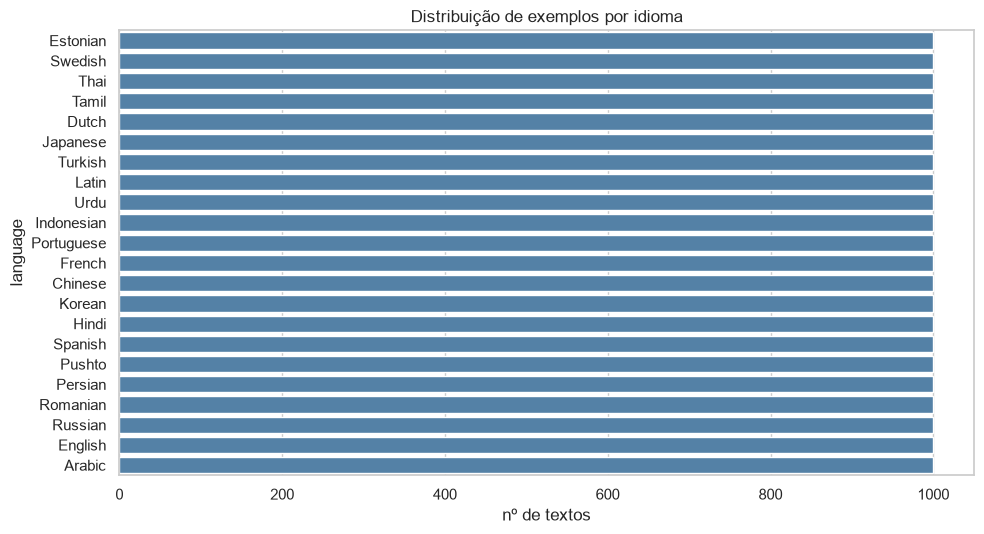

Rácio de desbalanceamento (max/min): 1.00


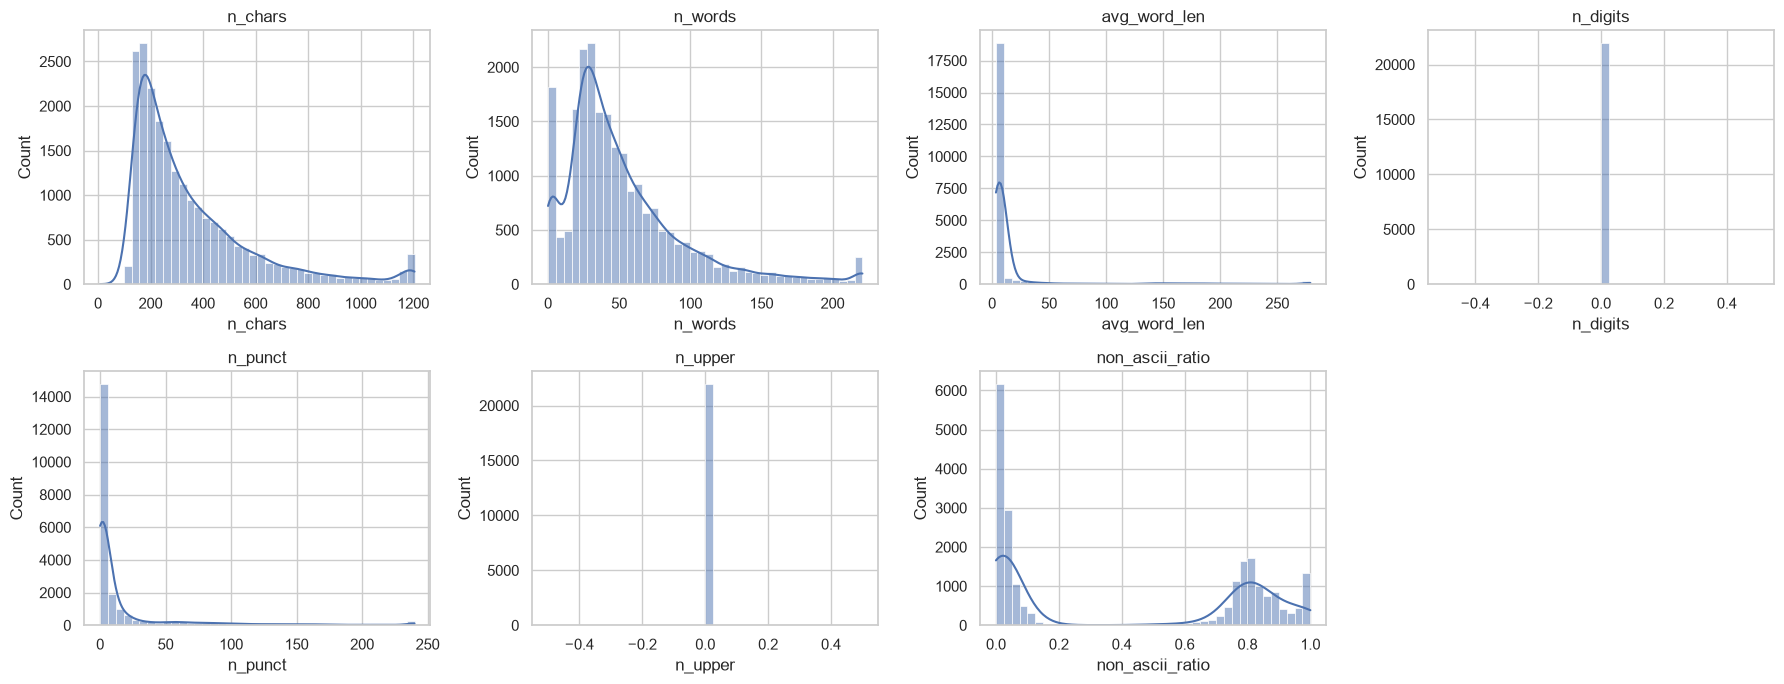

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
n_chars,22000.0,356.033,238.614,8.000,187.000,274.000,441.000,1341.0,1.790,3.251
n_words,22000.0,53.317,44.746,0.000,25.000,41.000,69.000,331.0,1.863,4.604
avg_word_len,21999.0,21.156,55.130,3.413,5.629,6.513,7.915,1084.0,5.181,36.129
n_digits,22000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.0,NaN,NaN
n_punct,22000.0,19.543,48.085,0.000,0.000,2.000,11.000,505.0,4.088,20.671
n_upper,22000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.0,NaN,NaN
non_ascii_ratio,22000.0,0.427,0.410,0.000,0.021,0.130,0.819,1.0,0.093,-1.884


In [18]:
counts = df[LABEL_COL].value_counts()
fig, ax = plt.subplots(figsize=(10, max(4, 0.25 * len(counts))))
sns.barplot(x=counts.values, y=counts.index, ax=ax, color="steelblue")
ax.set_title("Distribuição de exemplos por idioma"); ax.set_xlabel("nº de textos")
plt.tight_layout(); plt.show()
print(f"Rácio de desbalanceamento (max/min): {counts.max() / counts.min():.2f}")

feat = text_features(df[TEXT_COL]); feat[LABEL_COL] = df[LABEL_COL].values
num_cols = [c for c in feat.columns if c != LABEL_COL]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(feat[col].dropna().clip(upper=feat[col].quantile(0.99)), bins=40, ax=ax, kde=True); ax.set_title(col)
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

desc = feat[num_cols].describe().T
desc["skewness"] = feat[num_cols].skew(); desc["kurtosis"] = feat[num_cols].kurtosis()
desc.round(3)

> **Interpretação:** *skewness* > 1 indica cauda longa à direita (comum no comprimento de texto); *kurtosis* elevada indica outliers. Isto justifica o tratamento de outliers no Sprint 2 e o TF-IDF (que atenua o efeito do comprimento).

### Análise bivariada (feature × idioma)

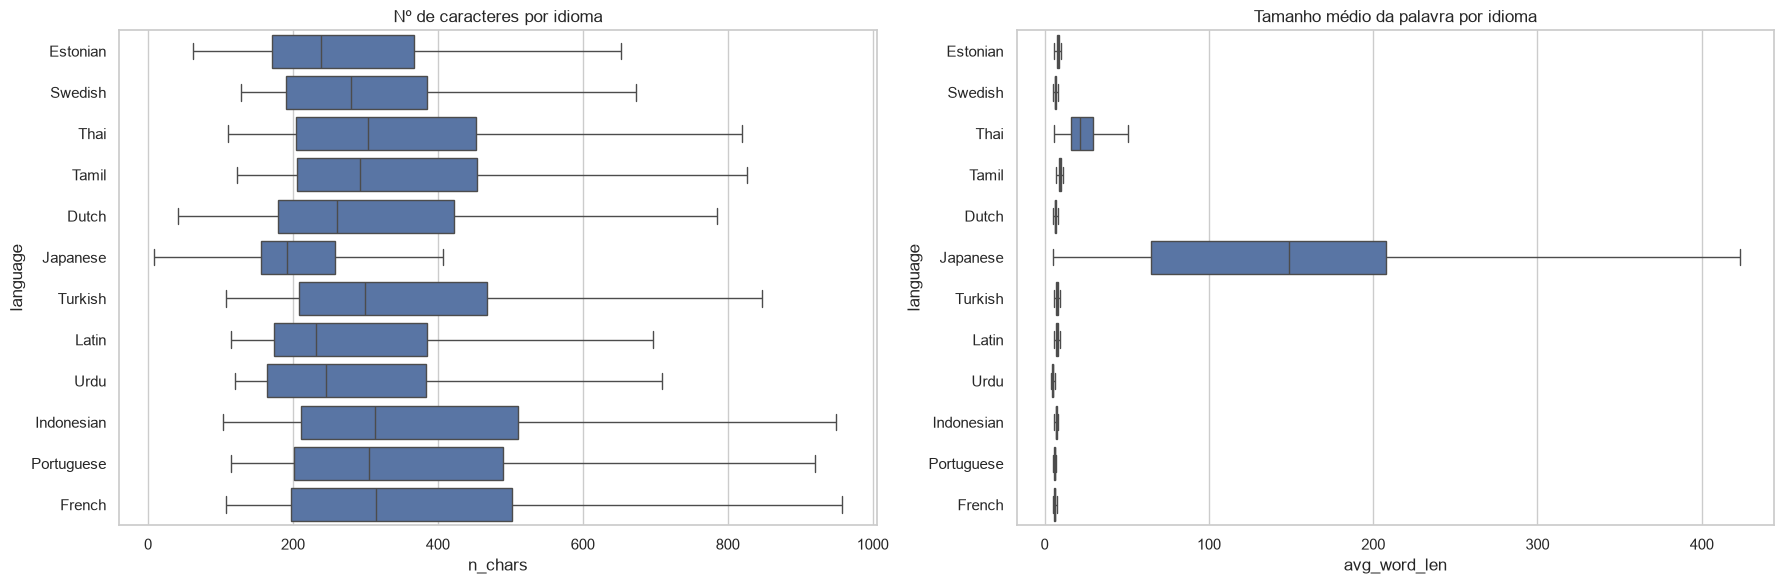

Kruskal-Wallis (n_chars ~ idioma): H=1667.8, p=0 -> diferenças significativas


In [19]:
top_langs = counts.index[:12]
sub = feat[feat[LABEL_COL].isin(top_langs)]
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.boxplot(data=sub, y=LABEL_COL, x="n_chars", ax=axes[0], showfliers=False); axes[0].set_title("Nº de caracteres por idioma")
sns.boxplot(data=sub, y=LABEL_COL, x="avg_word_len", ax=axes[1], showfliers=False); axes[1].set_title("Tamanho médio da palavra por idioma")
plt.tight_layout(); plt.show()

groups = [g["n_chars"].values for _, g in feat.groupby(LABEL_COL)]
H, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis (n_chars ~ idioma): H={H:.1f}, p={p:.3g} ->", "diferenças significativas" if p < 0.05 else "sem diferenças significativas")

### Análise multivariada + Pearson vs. Spearman

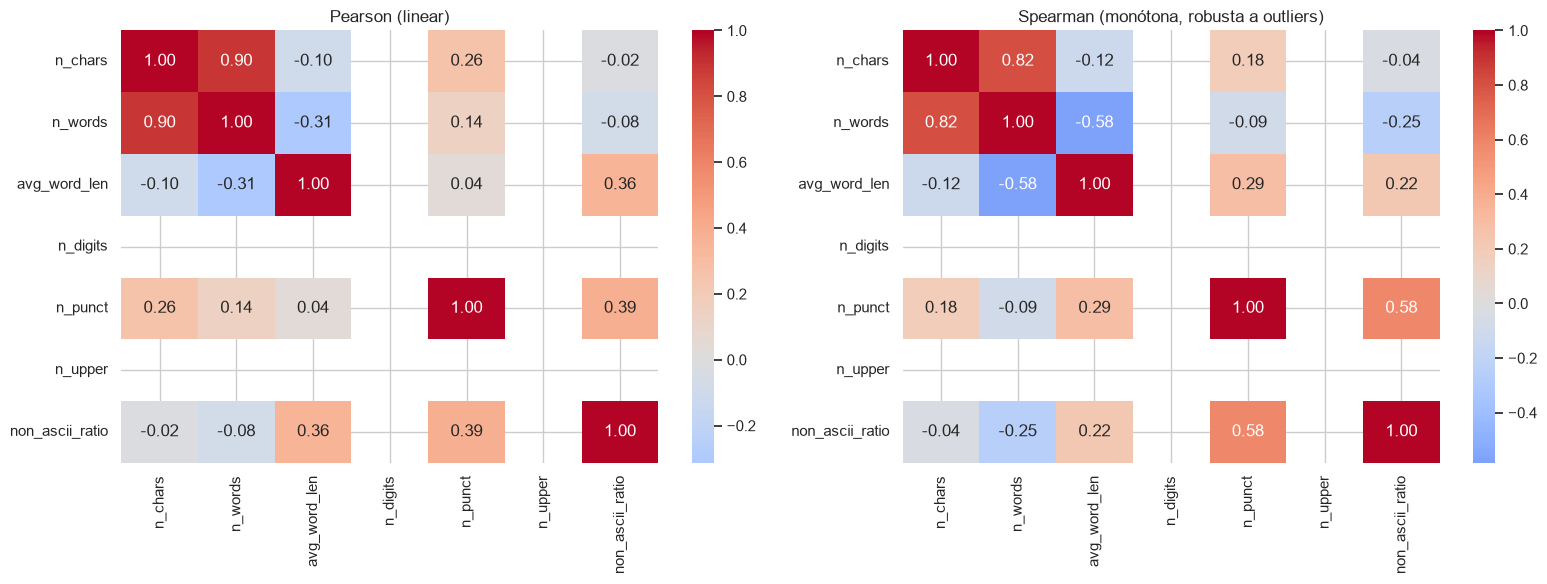

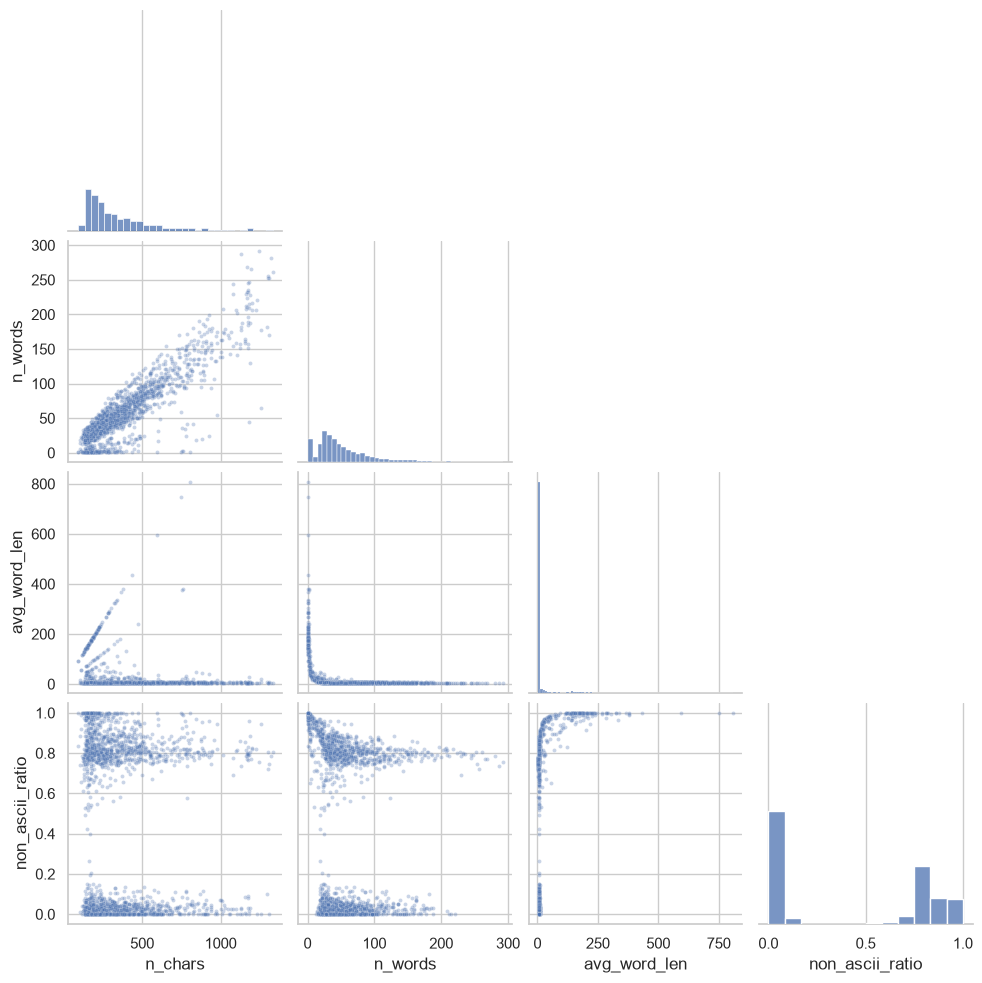

In [20]:
pear, spear = feat[num_cols].corr(method="pearson"), feat[num_cols].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pear, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0]); axes[0].set_title("Pearson (linear)")
sns.heatmap(spear, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1]); axes[1].set_title("Spearman (monótona, robusta a outliers)")
plt.tight_layout(); plt.show()

sample = feat.sample(min(2000, len(feat)), random_state=RANDOM_STATE)
sns.pairplot(sample, vars=["n_chars", "n_words", "avg_word_len", "non_ascii_ratio"], corner=True, plot_kws={"alpha": .3, "s": 8}); plt.show()

### Probabilidade condicional e Bayes — `P(idioma | script)`
Se o texto está em cirílico, restam poucos idiomas possíveis. O Naïve Bayes (Sprint 3) aplica exatamente o Teorema de Bayes: `P(idioma | texto) ∝ P(texto | idioma) · P(idioma)`.

Scripts encontrados: {'LATIN': 11192, 'ARABIC': 3927, 'CJK': 1405, 'CYRILLIC': 1002, 'HANGUL': 988, 'TAMIL': 987, 'THAI': 986, 'DEVANAGARI': 977, 'HIRAGANA': 426, 'KATAKANA': 109, 'NONE': 1}


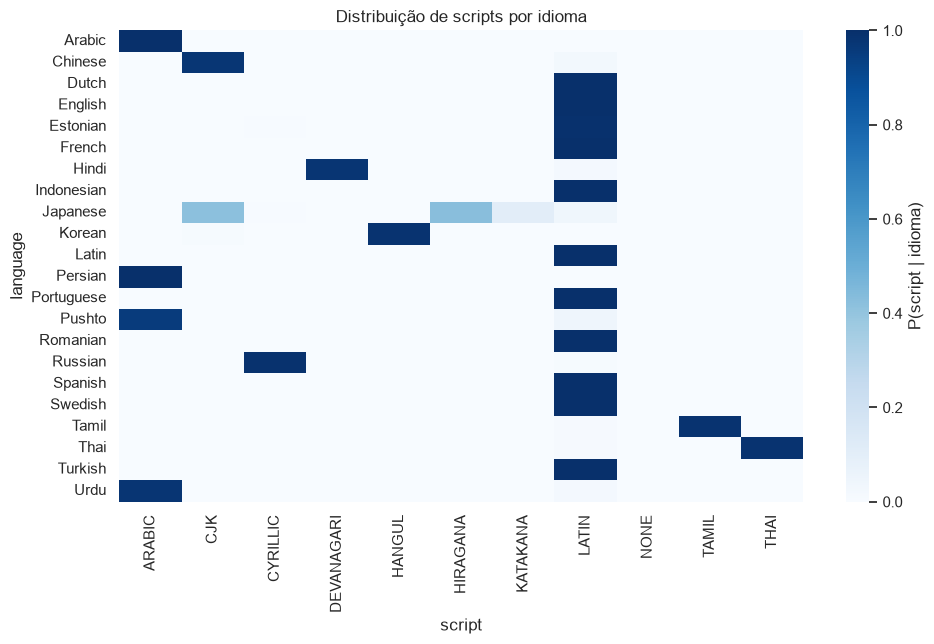

P(idioma | script=LATIN) top-3 -> {'French': 0.089, 'English': 0.089, 'Romanian': 0.089}
P(idioma | script=ARABIC) top-3 -> {'Persian': 0.254, 'Arabic': 0.254, 'Urdu': 0.249}
P(idioma | script=CJK) top-3 -> {'Chinese': 0.694, 'Japanese': 0.3, 'Korean': 0.006}
P(idioma | script=CYRILLIC) top-3 -> {'Russian': 0.99, 'Estonian': 0.004, 'Japanese': 0.004}
P(idioma | script=HANGUL) top-3 -> {'Korean': 1.0, 'Arabic': 0.0, 'Dutch': 0.0}


In [21]:
df["script"] = df[TEXT_COL].map(dominant_script)
ct = pd.crosstab(df[LABEL_COL], df["script"], normalize="index")
print("Scripts encontrados:", df["script"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(ct))))
sns.heatmap(ct, cmap="Blues", ax=ax, cbar_kws={"label": "P(script | idioma)"})
plt.title("Distribuição de scripts por idioma"); plt.tight_layout(); plt.show()

p_lang_given_script = pd.crosstab(df["script"], df[LABEL_COL], normalize="index")
for s in df["script"].value_counts().index[:5]:
    print(f"P(idioma | script={s}) top-3 ->", p_lang_given_script.loc[s].sort_values(ascending=False).head(3).round(3).to_dict())

## Conclusões do Sprint 1 (preencher)
- Nº de idiomas, tamanho do dataset, desbalanceamento: …
- Skewness/kurtosis do comprimento e decisão para outliers: …
- Pistas fortes (script, caracteres não-ASCII): …

**Próximo passo:** `02_Sprint2_Data_Preparation.ipynb`.